# Graph Models

The following demos using mol-miner-graphs. As of this writing, 2025.07.29, the package comes with four GNN algorithms - a general Graph Convolutional Neural Network (GNNNet), a Graph Isomorphism with Edge Features (GINENet), GraphSAGE (GSAGENet), and Graph Attention Network (GATNet). Additional Graph algorithms may be considered in the future.

The graph neural networks are called as a Class and share similar parameters. Of the networks, only the GINENet will utilize the edge_attr (i.e. bond types) as features when training the model. Otherwise, both Classes should be able to be able to be initialized and fit according to this tutorial. Only pertinent parameters to the author are shown, but each method contains additional parameters not shown here. Users are encouraged to dig into the documentation to explore further.

## Import Modules

In [1]:
import pandas as pd
from mminer_graphs import MolToGraph
from tqdm import tqdm
from mminer_graphs.model import GCNNet, GINENet, GSAGENet, GATNet, EarlyStopping
from mminer_graphs import Plots
from torch_geometric.loader import DataLoader
from mminer_graphs.model.model_utils import set_seed

Optional script to check if CUDA is installed on your machine. By default, the model will train using the system GPU. However, CPU can be specified.

In [2]:
# import torch
# print(torch.cuda.is_available())
# print(torch.cuda.get_device_name(0))

## Dataset Prep
The sample dataset is taken from [MoleculeNet](https://moleculenet.org) and uses their BACE dataset. This dataset includes quantitative (IC50) and qualitative (binary labels) binding results for inhibitors of human beta secretase (BACE-1). The only modification the dataset was replacing their default split with a random split and including cross-validation columns with random splits. There are other datasets that can also be included during model training and will be discussed under the [Extra Features]() section.

In this case, a model will be created using a single split (Model). After extracting the necessary information, the Data will contain the following format:

In [3]:
data = pd.read_csv("dataset/bace.csv")
cols = ['CID', 'smiles', 'Class', 'Model']
dataset = data[cols]
print(f"The shape of the dataset: {dataset.shape}")
dataset.head()

The shape of the dataset: (1513, 4)


,CID,smiles,Class,Model
0,BACE_1,O1CC[C@@H](NC(=O)[C@@H](Cc2cc3cc(ccc3nc2N)-c2c...,1,train
1,BACE_2,Fc1cc(cc(F)c1)C[C@H](NC(=O)[C@@H](N1CC[C@](NC(...,1,train
2,BACE_3,S1(=O)(=O)N(c2cc(cc3c2n(cc3CC)CC1)C(=O)N[C@H](...,1,train
3,BACE_4,S1(=O)(=O)C[C@@H](Cc2cc(O[C@H](COCC)C(F)(F)F)c...,1,train
4,BACE_5,S1(=O)(=O)N(c2cc(cc3c2n(cc3CC)CC1)C(=O)N[C@H](...,1,train


The dataset will need to be converted into graphs. Here, the data will be split into the train and test set (or also a validation set, but this is not used here). Using the MolToGraph() method, the molecules will be converted into graphs. By default, the AtomGraph will be used. Afterward, this information will be fed into the

In [4]:
train = dataset[dataset.iloc[:, -1] == 'train']
test = dataset[dataset.iloc[:, -1] == 'test']

train_graphs = [MolToGraph(smi=smi, label=y).graph_data for smi, y in tqdm(zip(train.smiles, train.Class), desc="Converting Train Graphs")]
test_graphs = [MolToGraph(smi=smi, label=y).graph_data for smi, y in tqdm(zip(test.smiles, test.Class), desc="Converting Test Graphs")]

Converting Train Graphs: 1376it [00:02, 518.10it/s]
Converting Test Graphs: 137it [00:00, 523.00it/s]


*Optional*

To get the model working, all you need is a list of the graph data. Internally, the model classes will convert this into a PyTorch Geometric DataLoader class. However, to show users how the graph data list is converted into a DataLoader class, it will be utilized in this tutorial. If this section is removed, the following cells before calling the GNN Class will also need to be removed.

In [5]:
# load data
train_graphs = DataLoader(train_graphs, batch_size=1024, shuffle=True, worker_init_fn=set_seed(42)) # avoid overfitting to sample order
test_graphs = DataLoader(test_graphs, batch_size=1024)

print(f"Training Data: {len(train_graphs.dataset)}")
print(f"Test Data: {len(test_graphs.dataset)}")

Training Data: 1376
Test Data: 137


The graph information set as a DataLoader can be visualized using .dataset. This will generate a list of the graph data. Only the first 5 are printed to save space.

In [6]:
train_graphs.dataset[:5]

[Data(x=[32, 142], edge_index=[2, 70], edge_attr=[70, 16], y=[1]),
 Data(x=[47, 142], edge_index=[2, 100], edge_attr=[100, 16], y=[1]),
 Data(x=[42, 142], edge_index=[2, 92], edge_attr=[92, 16], y=[1]),
 Data(x=[40, 142], edge_index=[2, 84], edge_attr=[84, 16], y=[1]),
 Data(x=[44, 142], edge_index=[2, 96], edge_attr=[96, 16], y=[1])]

A single data can be visualized as follows.

In [7]:
train_graphs.dataset[0]

Data(x=[32, 142], edge_index=[2, 70], edge_attr=[70, 16], y=[1])

## Training the Model

To train the model, the network class must be instantiated. There are several parameters needed to ensure that the model runs without issue. By default, the parameters will be set to utilize the AtomGraph, but can be changed to encompass different molecular graph data. For clarity, the necessary information will be given where applicable.

In this example, the GCNNet is called. The node dimensions corresponds to the input features for the graph. For AtomGraph, that is 142. The hidden_dim sets graph feature vector output for the layer. If the parameter ***reduce_graph*** is set to True, then the graph feature vector will be halved in each subsequent graph layer. In this example, each graph layer feature vector will be set to 128. The ***graph_layers*** parameter will set the number of graph layers. The output feature vectors will match the hidden_dim and reduce_graph parameters settings. The final graph latent vector will be generated and fed into the MLP layers.

Next, the ***mlp_layers*** parameter will set the number of layers to use in the MLP section of the model. By default, the number of nodes in the first MLP layer will be set to the output of the graph latent vector. This will be halved for each subsequent layer. A dropout can be initiated in the MLP layers. In this example, the graph_dropout and mlp_dropout is set to 0.

Finally, the class includes a ***num_classes*** parameter. This will set the number of classes in the final output layer. For classification this is set to 2.

**NOTE:** The code has not been tested for multi-label or regression models.

In [8]:
model = GCNNet(node_dim=142, hidden_dim=128, graph_layers=3, mlp_layers=2, reduce_graph=False, mlp_dropout=0, num_classes=2)

The GCNNet class above was set to the variable **model**. This can be printed to check on the created model. This will print out the model, its graph and its MLP layers

In [9]:
model

GCNNet(
  (gcn_conv): ModuleList(
    (0): GCNConv(142, 128)
    (1-2): 2 x GCNConv(128, 128)
  )
  (mlp): ModuleList(
    (0): Sequential(
      (0): Linear(in_features=128, out_features=64, bias=True)
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Dropout(p=0, inplace=False)
    )
  )
  (final_mlp): Linear(in_features=64, out_features=2, bias=True)
)

**EarlyStopping** can also be used. Here it will be called to monitor the validation/test data.

In this tutorial, the **EarlyStopping** class is instantiated, but the patience is set at 350. It is only used here to give an example of how to use it. Its patience can be set accordingly.

In [10]:
estop = EarlyStopping(monitor='val_loss', patience=350, mode='min')

The model can be fit in a similar fashion to the sklearn api by calling the **.fit()** instance method. There are several mandatory parameters needed to ensure that the model is fitted:
- The instantiated model
- The training dataset
- The test dataset

Additional parameters include setting the epochs number, the optimizer, and using early stopping (estop). A special parameter, **device** will determine where the tensors are to be trained. By default, this is set to "Auto" and will utilize the machine's gpu. However, this can be individually set as 'cpu', 'gpu', 'cuda', or 'mps'. Setting the device to 'gpu' is equivalent to 'cuda'. For Macs, the 'mps' will is needed.

In this example, all models will be trained using the cpu.

In [11]:
model.fit(model, train_graphs, test_graphs, epochs=350, optimizer="adam", device='cpu', estop=estop)

Model and Tensor running on cpu


Epoch: 100%|██████████| 350/350 [01:14<00:00,  4.71it/s]

Average Training Loss: 0.187
Average Test Loss: 2.131
Average Training Accuracy: 0.921
Average Test Accuracy: 0.635


GCNNet(
  (gcn_conv): ModuleList(
    (0): GCNConv(142, 128)
    (1-2): 2 x GCNConv(128, 128)
  )
  (mlp): ModuleList(
    (0): Sequential(
      (0): Linear(in_features=128, out_features=64, bias=True)
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Dropout(p=0, inplace=False)
    )
  )
  (final_mlp): Linear(in_features=64, out_features=2, bias=True)
)

Once the model is fitted, basic metrics will be printed. This will include the average loss and accuracy for the training and test dataset

## Plots

The mol-miner-graphs comes with basic plot functions. This section will demo their usage.

### Curves
The **curves()** method will generate the loss curve and accuracy curves for the model. It will use the results from the Test data. The figure here is drawn with default settings, however the **curves()** method contains additional parameters, such as line colors, figsize, or other metrics to plot (Precision).

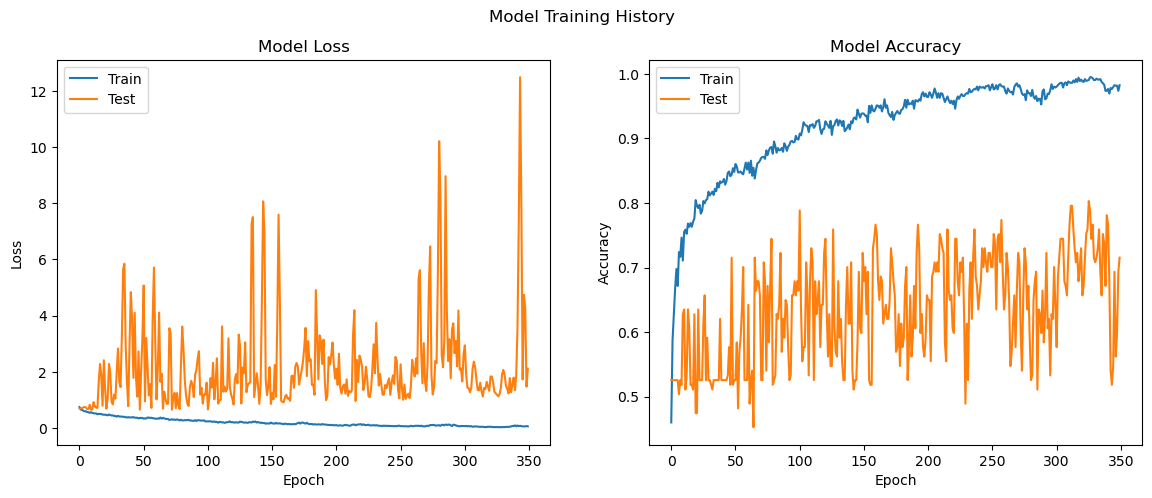

In [12]:
plot = Plots(model, data_loader=test_graphs)

plot.curves()

### Confusion Matrix

A confusion matrix can be drawn using the **confusion_matrix()** method. The class names will default to 0 and 1. Here, they are renamed as "Inactive" and "Active" using the **class_names** parameter. The device is an important parameter and should be modified to use the same as the model fitting. For example, if the model was fitted using 'cpu', then the confusion matrix device should be set to 'cpu'. Additional parameters are available to modify the title, figsize, and cmap.

Prediction running on cpu


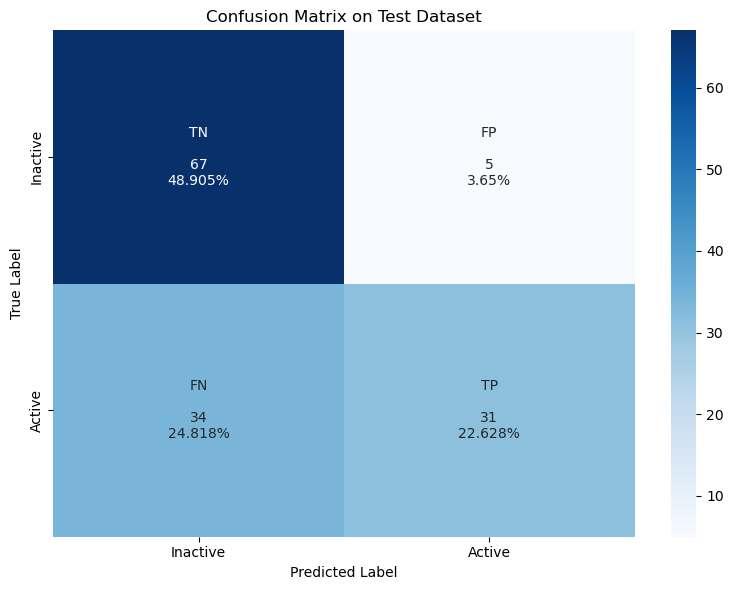

In [13]:
plot.confusion_matrix(class_names=['Inactive', 'Active'], device='cpu')

### Classificaiton Report
A classification report can also be generated. The parameters are similar to the **confusion_matrix()** method.

Prediction running on cpu


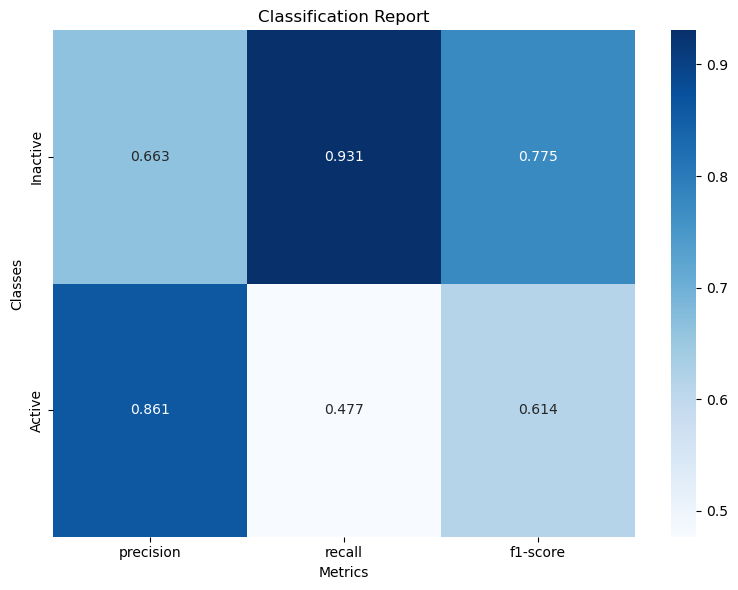

In [14]:
plot.classification_report(class_names=['Inactive', 'Active', ], device='cpu')

## Making Predictions

Additionally, the mol-miner-graphs package contains a **.predict()** for easier usability. This will output a list of results on a tensor. By default, the **.predict()** method  it will output results as a list for easier use with pd.DataFrames. In this example, the results are given as a tensor. Users that wish to append this to a pd.DataFrame will need to convert the results using **.tolist()**

In [15]:
model.predict(model, test_graphs, device='cpu', return_type="tensor", binary=True)

Prediction running on cpu


tensor([0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1,
        1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1,
        0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0])

## Adding Extra Features
The above shows general usage with mol-miner-graphs. In some cases, a graph model may not be "descriptive" enough for a given dataset. The graph latent space can be appended in hopes to add more descriptive features before training the MLP layers. On a tensor, this information will be added under the "add_feats". The models in this package will append any data under the labels of add_feats to the graph latent space vector, which will subsequently be used in an MLP neural network.

### Data Prep
In this example, three additional descriptors will be added from the bace.csv dataset. The information must be converted into a list and appended to the data before proceeding.

In [16]:
# extra features
extra_cols = ["pIC50", "MW", "AlogP", "HBA", "HBD", "RB", "HeavyAtomCount", "ChiralCenterCount",
              "ChiralCenterCountAllPossible", "RingCount"]
extra_data = data[extra_cols]
extra_list = extra_data.values.tolist()

The additional features can be added when converting the smiles strings into molecular graphs. This requires adding the list of additional features under the **add_feats** parameter.

In [17]:
# create array of graphs for train/test
train_graphs = [MolToGraph(smi=smi, label=y, add_feats=extra).graph_data for smi, y, extra in tqdm(zip(train.smiles, train.Class, extra_list), desc="Converting Train Graphs")]
test_graphs = [MolToGraph(smi=smi, label=y, add_feats=extra).graph_data for smi, y, extra in tqdm(zip(test.smiles, test.Class, extra_list), desc="Converting Test Graphs")]

Converting Train Graphs: 1376it [00:02, 485.39it/s]
Converting Test Graphs: 137it [00:00, 523.63it/s]


### Add Feats Example
To visualize what this would look like, 5 graphs from the train_graphs list will be shown. Notice how the data contains additional information under add_feats. This number corresponds to the number of additional features added to the molecular graphs.

In [18]:
train_graphs[:5]

[Data(x=[32, 142], edge_index=[2, 70], edge_attr=[70, 16], y=[1], add_feats=[10]),
 Data(x=[47, 142], edge_index=[2, 100], edge_attr=[100, 16], y=[1], add_feats=[10]),
 Data(x=[42, 142], edge_index=[2, 92], edge_attr=[92, 16], y=[1], add_feats=[10]),
 Data(x=[40, 142], edge_index=[2, 84], edge_attr=[84, 16], y=[1], add_feats=[10]),
 Data(x=[44, 142], edge_index=[2, 96], edge_attr=[96, 16], y=[1], add_feats=[10])]

### Training the Model

In this example, the Graph Isomorphism with Edge Features Network (GINENet) will be called. Unlike the above model, this one will consider edge features. The **edge_feat_dim** param must match the number of features in teh edge_attr from the molecular graph. Otherwise, the parameters in the **GINENet()** should be similar to what is found in the **GCNNet()** class. The add_feats parameter, which is shown in this section, should also be available with the GCNNet() class. In this case, the **add_feats** parameter can be a list of the additional features, such as the list *extra_list* generated above, or it can be an int denoting the length of the list. In this example, an int of 10 will be used.

In [19]:
model = GINENet(node_dim=142, edge_feat_dim=16, hidden_dim=128, graph_layers=3, mlp_layers=2, reduce_graph=False, graph_dropout= 0, mlp_dropout=0, num_classes=2, add_feats=10)

In [20]:
model

GINENet(
  (gine_conv): ModuleList(
    (0): GINEConv(nn=Sequential(
      (0): Linear(in_features=142, out_features=128, bias=True)
      (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Linear(in_features=128, out_features=128, bias=True)
      (4): ReLU()
    ))
    (1-2): 2 x GINEConv(nn=Sequential(
      (0): Linear(in_features=128, out_features=128, bias=True)
      (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Linear(in_features=128, out_features=128, bias=True)
      (4): ReLU()
    ))
  )
  (mlp): ModuleList(
    (0): Sequential(
      (0): Linear(in_features=138, out_features=69, bias=True)
      (1): BatchNorm1d(69, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Dropout(p=0, inplace=False)
    )
  )
  (final_mlp): Linear(in_features=69, out_features=2, bias=True)
)

### Fitting the Model

Because the GINENet model was instantiated with a list of molecular features instead of a PyG DataLoader, batch size must be set in the **.fit()** method. The model will internally convert the list of molecular graphs as a DataLoader. In this example, the batch_size is set to 1024. The other parameters should be the same as used above.

In [21]:
model.fit(model, train_graphs, test_graphs, epochs=350, batch_size=1024, optimizer="adam", device='cpu', estop=estop)

Model and Tensor running on cpu


Epoch: 100%|██████████| 350/350 [02:07<00:00,  2.75it/s]

Average Training Loss: 0.075
Average Test Loss: 1.622
Average Training Accuracy: 0.968
Average Test Accuracy: 0.784


GINENet(
  (gine_conv): ModuleList(
    (0): GINEConv(nn=Sequential(
      (0): Linear(in_features=142, out_features=128, bias=True)
      (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Linear(in_features=128, out_features=128, bias=True)
      (4): ReLU()
    ))
    (1-2): 2 x GINEConv(nn=Sequential(
      (0): Linear(in_features=128, out_features=128, bias=True)
      (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Linear(in_features=128, out_features=128, bias=True)
      (4): ReLU()
    ))
  )
  (mlp): ModuleList(
    (0): Sequential(
      (0): Linear(in_features=138, out_features=69, bias=True)
      (1): BatchNorm1d(69, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Dropout(p=0, inplace=False)
    )
  )
  (final_mlp): Linear(in_features=69, out_features=2, bias=True)
)

Similarly, the fitted GINENet model metrics can be plotted. Here the Loss and Accuracy curves will be generated.

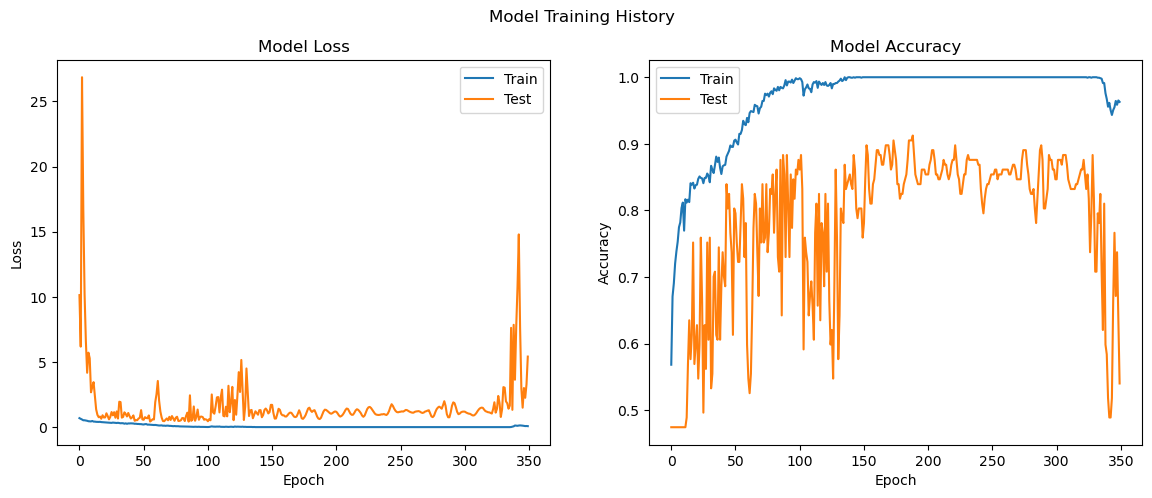

In [22]:
plot = Plots(model, data_loader=test_graphs)

plot.curves()

## Additional Graph Algorithms
The mol-miner-graphs contains two additional graph neural network algorithms. They share similar parametesrs as seen with the models called above in the tutorial. Here, an example is show for Graph Attention Network (GATNet) and GraphSAGE network (GSAGENet).

In [23]:
model = GATNet(node_dim=142, edge_feat_dim=16, hidden_dim=128, graph_layers=2, mlp_layers=2, mlp_dropout=0, num_classes=2, heads=1,
               reduce_graph=False, add_feats=10)
model

GATNet(
  (gat_conv): ModuleList(
    (0): GATConv(142, 128, heads=1)
    (1): GATConv(128, 128, heads=1)
  )
  (mlp): ModuleList(
    (0): Sequential(
      (0): Linear(in_features=138, out_features=69, bias=True)
      (1): BatchNorm1d(69, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Dropout(p=0, inplace=False)
    )
  )
  (final_mlp): Linear(in_features=69, out_features=2, bias=True)
)

In [24]:
model = GSAGENet(node_dim=142, hidden_dim=128, graph_layers=2, mlp_layers=2, mlp_dropout=0, num_classes=2, reduce_graph=False, add_feats=10)
model

GSAGENet(
  (sage_conv): ModuleList(
    (0): SAGEConv(142, 128, aggr=mean)
    (1): SAGEConv(128, 128, aggr=mean)
  )
  (mlp): ModuleList(
    (0): Sequential(
      (0): Linear(in_features=138, out_features=69, bias=True)
      (1): BatchNorm1d(69, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Dropout(p=0, inplace=False)
    )
  )
  (final_mlp): Linear(in_features=69, out_features=2, bias=True)
)